# Bayesian Partial Pooling of County Poverty Estimates — What the Model Adds and What the Prior Adds

**Artifact class:** `tutorial`  ·  **Data mode:** `empirical`  ·  **Vintage:** ACS 2023 5-year estimates (2019 to 2023), table `B17001`, Virginia

This notebook uses **real data only**. There is no synthetic generator and no fallback. A county's published poverty estimate carries a margin of error, and the margins differ by an order of magnitude across the 133 counties and independent cities of Virginia. A hierarchical model borrows strength across them: each county's estimate is pulled toward the state mean in proportion to how noisy it is. The notebook fits that model with `pymc` (an optional extra), shows the pooled and the unpooled estimates **side by side**, and measures how much of the difference is the data and how much is the prior.

The analysis was fixed in a written plan (`pap/Q03_pap.md`) committed alone before any retrieval, and one amendment (`pap/Q03_pap_amendment_1.md`: retained draws raised from 2000 to 8000) committed after the first fit stopped on its effective-sample-size floor and before any rerun. A pooled estimate is a **model output** that inherits its prior (methodology section 1, the regime of modelled estimates); the unpooled estimate is design-based and inherits nothing. This notebook ranks no county.

*Proprietary. SPDX-License-Identifier: LicenseRef-Proprietary*

## Learning Objectives

By the end of this notebook you will be able to:

1. Write the normal-normal hierarchical model for estimates with known standard errors, and say what its shrinkage factor is.
2. Convert two ACS margins of error into the standard error of a proportion.
3. Check a sampler three ways: convergence diagnostics, an exact calculation that needs no sampling, and a posterior predictive coverage check.
4. Show a prior's contribution by refitting under other priors, and report which counties' estimates are mostly the prior.

## Prerequisites

**Knowledge.** Margins of error and standard errors; the idea of a prior and a posterior; notebook D04 for the reliability framework (the moment estimator of between-county variance). **Software.** The `pymc` extra: `pip install -e '.[notebooks,pymc]'`. **Data access.** A Census API key, read from the environment or from the reader's own key file (see the README); it is never printed here.

## Data Provenance

| Item | Meaning | Role |
|---|---|---|
| `B17001_001E`, `B17001_001M` | poverty universe and its margin of error | denominator |
| `B17001_002E`, `B17001_002M` | persons below the poverty level and its margin of error | numerator |

Source: Census Bureau ACS 5-year estimates, 2023 vintage, `county:*` within `state:51`, through `fetch_acs`: **the request notebook D04 makes**, whose stored digest this notebook compares with its own rows before using them. The record is in `provenance/`, bound to the plan by its digest, and the run is on the ledger beside it.

## Design

**Estimand.** The true 2019 to 2023 poverty rate `theta_i` of each of the 133 places. Two estimates are shown for every place: the unpooled published estimate with its margin of error, and the pooled posterior.

**Model** (on the rate scale, non-centred, fixed before the data):

`y_i ~ Normal(theta_i, s_i)` with `s_i` known; `theta_i = mu + tau * z_i`, `z_i ~ Normal(0, 1)`; `mu ~ Normal(0.15, 0.10)`; `tau ~ HalfNormal(0.05)`.

The **shrinkage factor** `B_i = s_i^2 / (s_i^2 + tau^2)` is the weight a place's estimate puts on the state mean: near one for a noisy county, near zero for a precise one. It is the reliability `1 - lambda_i` of notebook D04, under this model. Because `mu` integrates out in closed form, the posterior of every `theta_i` can also be computed **exactly** by integrating over `tau` on a grid; that calculation, in `krl_tutorials_data.methods.pooling`, has no sampler in it and is the independent check on the sampler.

**Stop rules** (plan section 4). The notebook stops, prints its diagnostics and asks the owner if the largest R-hat exceeds 1.01, a divergent transition remains, or the smallest effective sample size is below 400. **Checks** (plan section 6) are printed as `FALSIFICATION:` lines, and a check that fails is reported as such.

In [1]:
"""Configuration. Every analytic choice is named here, not inferred."""
from __future__ import annotations

import hashlib
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
from scipy import stats as st

_here = Path.cwd().resolve()
for _cand in (_here, *_here.parents):
    if (_cand / "src" / "krl_tutorials_data").is_dir():
        sys.path.insert(0, str(_cand / "src"))
        REPO_ROOT = _cand
        break
else:
    raise SystemExit("Could not locate krl_tutorials_data from " + str(_here))

from krl_tutorials_data import provenance
from krl_tutorials_data.methods import pooling
from krl_tutorials_data.sources import DataAccessError, fetch_acs

NB_DIR = REPO_ROOT / "projects" / "11-distribution-heterogeneity" / "Q03_bayesian_pooling_county_estimates"
PLAN = NB_DIR / "pap" / "Q03_pap.md"
AMEND = [NB_DIR / "pap" / "Q03_pap_amendment_1.md"]       # draws 2000 -> 8000 after the first fit stopped (committed before the rerun)
PLAN_SHA256 = hashlib.sha256(PLAN.read_bytes()).hexdigest()
D04_DIR = REPO_ROOT / "projects" / "02-health-housing" / "D04_health_prevalence"
provenance.use_ledger(NB_DIR / "provenance" / "_runs.jsonl", PLAN, *AMEND)   # every fetch below is appended to the run ledger


def stop(message: str) -> None:
    """Append a stopped line to the run ledger, then raise."""
    provenance.ledger_stop(message)
    raise SystemExit(message)


YEAR, STATE_FIPS = 2023, "51"
SEED = 20261030
CHAINS, TUNE, DRAWS, TARGET_ACCEPT = 4, 2000, 8000, 0.95      # DRAWS is 2000 in the plan, 8000 in amendment 1
PRIOR_SETTINGS = {                                        # plan section 5: label -> (mu prior, tau prior)
    "primary": ((0.15, 0.10), ("halfnormal", 0.05)),
    "tight tau": ((0.15, 0.10), ("halfnormal", 0.02)),
    "loose tau": ((0.15, 0.10), ("halfnormal", 0.15)),
    "heavy-tailed tau": ((0.15, 0.10), ("halfcauchy", 0.05)),
    "vague mu": ((0.15, 0.30), ("halfnormal", 0.05)),
}
MIN_COUNTIES = 120                                        # plan section 2
RHAT_STOP, ESS_MIN = 1.01, 400                            # plan section 4
EXACT_TOL_PP, MU_TOL_PP, SENSITIVE_PP = 0.1, 0.5, 1.0     # plan sections 6 and 5
COVER_LO, COVER_HI, LEVEL = 0.85, 0.95, 0.90
LAMBDA_MIN = 0.7                                          # D04's publishing convention
TARGET = "rate"

print(f"pre-analysis plan : {PLAN.relative_to(REPO_ROOT)}")
print(f"plan SHA-256      : {PLAN_SHA256}")
print(f"vintage           : ACS {YEAR} 5-year, Virginia (state:{STATE_FIPS})")
print(f"seed {SEED}; NUTS, {CHAINS} chains, {TUNE} tuning and {DRAWS} retained draws each, target_accept {TARGET_ACCEPT}")
print(f"pymc {pm.__version__}")

pre-analysis plan : projects/11-distribution-heterogeneity/Q03_bayesian_pooling_county_estimates/pap/Q03_pap.md
plan SHA-256      : 526398744e0d0a38b65756e9bcb8d565d8f393430f051acb3e8817ae7c7da596
vintage           : ACS 2023 5-year, Virginia (state:51)
seed 20261030; NUTS, 4 chains, 2000 tuning and 8000 retained draws each, target_accept 0.95
pymc 6.3.2


### Retrieving the table, and checking it is D04's table

The request is D04's, unchanged. The digest of the rows is compared with the digest D04 stored for the same request. If they differ, Census has changed the file and the notebook stops.

In [2]:
LABELS = {"B17001_001E": "poverty universe", "B17001_001M": "poverty universe MOE",
          "B17001_002E": "persons in poverty", "B17001_002M": "persons in poverty MOE"}
try:
    poverty, prov = fetch_acs(year=YEAR, variables=LABELS, geography="county:*", within=f"state:{STATE_FIPS}")
except DataAccessError as exc:
    print("HALTED - real data could not be obtained.")
    print(f"  failure class : {type(exc).__name__}")
    print(f"  detail        : {exc}")
    stop(f"data access failed: {type(exc).__name__}")
prov.with_pap_chain(PLAN, *AMEND).write(NB_DIR / "provenance" / "q03_acs_b17001_county.json")

theirs = json.loads((D04_DIR / "provenance" / "d04_acs_b17001_county.json").read_text(encoding="utf-8"))["content_sha256"]
same = prov.content_sha256 == theirs
print(prov.render())
print(f"\nrows here {prov.content_sha256[:12]}, D04's {theirs[:12]}, identical: {same}")
print(f"FALSIFICATION: data_identity statistic={int(same)} of 1 request whose rows have the digest D04 stored verdict={'PASS' if same else 'FAIL'}")
if not same:
    stop("the rows differ from D04's stored digest; Census may have changed the file; ask the owner")

Source      : U.S. Census Bureau - American Community Survey (acs/acs5)
Vintage     : 2023  (pinned)
Endpoint    : https://api.census.gov/data/2023/acs/acs5
Retrieved   : 2026-10-30T11:51:43+00:00
Shape       : 133 rows x 7 cols
Payload hash: de80c3ee9645ba78...  (canonical-rows)
Data mode   : EMPIRICAL
Variables   :
              B17001_001E      poverty universe
              B17001_001M      poverty universe MOE
              B17001_002E      persons in poverty
              B17001_002M      persons in poverty MOE
Limitations :
              - ACS estimates are survey-based. Their margins of error were requested with the estimates (B17001_001M, B17001_002M) and are returned as columns; differences between geographies may not be statistically distinguishable.
              - Jam values (suppressed / unavailable estimates) were converted to missing. Sentinels recognised: [-999999999, -888888888, -777777777, -666666666, -555555555, -333333333, -222222222, -111111111].
              - 5

### From two margins of error to one standard error

Each county's estimate is `y_i = persons in poverty / poverty universe`. Its standard error comes from the Census Bureau's formula for a proportion whose numerator is part of its denominator, using both published margins (each at 90% confidence, so `se = MOE / 1.645`). A county with a missing or non-positive value is dropped and counted.

In [3]:
data = poverty.copy()
cols = list(LABELS)
for c in cols:
    data[c] = pd.to_numeric(data[c], errors="coerce")
    data.loc[data[c] < 0, c] = np.nan                       # Census annotation codes are large negative numbers
data["n"] = data["B17001_001E"]
data["y"] = data["B17001_002E"] / data["n"]
data["s"] = pooling.proportion_se(data["B17001_002E"], data["B17001_002M"], data["n"], data["B17001_001M"])
usable = np.isfinite(data["y"]) & np.isfinite(data["s"]) & (data["s"] > 0) & (data["n"] > 0)
print(f"{len(data)} places retrieved; {int((~usable).sum())} dropped (missing or non-positive value)")
data = data[usable].reset_index(drop=True)
if len(data) < MIN_COUNTIES:
    stop(f"only {len(data)} places remain; the plan stops below {MIN_COUNTIES}")
data["place"] = data["NAME"].str.replace(r", Virginia$", "", regex=True)
Y, S, N = data["y"].to_numpy(float), data["s"].to_numpy(float), data["n"].to_numpy(float)
assert pd.Series(Y).var() > 0, "the estimates must vary"
print(f"{len(data)} places kept; poverty universe from {int(N.min()):,} to {int(N.max()):,} people")
print(f"unpooled rate: median {100 * np.median(Y):.1f}, range {100 * Y.min():.1f} to {100 * Y.max():.1f} percent")
print(f"standard error: median {100 * np.median(S):.2f}, range {100 * S.min():.2f} to {100 * S.max():.2f} percentage points "
      f"(a ratio of {S.max() / S.min():.0f} between the noisiest and the most precise place)")
tau2_mm = pooling.moment_tau2(Y, S)
print(f"moment estimate of between-county spread tau = {100 * np.sqrt(tau2_mm):.2f} percentage points (D04's estimator)")

133 places retrieved; 0 dropped (missing or non-positive value)
133 places kept; poverty universe from 2,261 to 1,133,376 people
unpooled rate: median 11.6, range 3.3 to 33.7 percent
standard error: median 1.41, range 0.21 to 5.03 percentage points (a ratio of 24 between the noisiest and the most precise place)
moment estimate of between-county spread tau = 5.76 percentage points (D04's estimator)


## 1. The model, fitted

The model is fitted with NUTS, four chains run one after another so that the run is reproducible under the seed. The convergence stop rule is applied to every fit in this notebook, before any number from it is used.

In [4]:
def fit(mu_prior, tau_prior, y, s, predictive=False):
    """Fit the plan's hierarchical model and return the ArviZ data tree."""
    with pm.Model():
        mu = pm.Normal("mu", mu_prior[0], mu_prior[1])
        tau = pm.HalfNormal("tau", tau_prior[1]) if tau_prior[0] == "halfnormal" else pm.HalfCauchy("tau", tau_prior[1])
        z = pm.Normal("z", 0.0, 1.0, shape=len(y))
        theta = pm.Deterministic("theta", mu + tau * z)
        pm.Normal("obs", theta, s, observed=y)
        tree = pm.sample(draws=DRAWS, tune=TUNE, chains=CHAINS, cores=1, target_accept=TARGET_ACCEPT,
                         random_seed=SEED, progressbar=False)
        if predictive:                                  # replicate estimates drawn by pymc under the same seed
            pm.sample_posterior_predictive(tree, random_seed=SEED, progressbar=False, extend_inferencedata=True)
        return tree


def worst(tree_stat) -> float:
    ds = tree_stat.dataset
    return max(float(ds[v].max()) for v in ds.data_vars)


def least(tree_stat) -> float:
    ds = tree_stat.dataset
    return min(float(ds[v].min()) for v in ds.data_vars)


def diagnostics(idata, label):
    """R-hat, effective sample sizes, divergences and BFMI; stop on the plan's rules."""
    names = ["mu", "tau", "theta"]
    rhat = pm.stats.rhat(idata, var_names=names)
    ess_b = pm.stats.ess(idata, var_names=names, method="bulk")
    ess_t = pm.stats.ess(idata, var_names=names, method="tail")
    div = int(idata["sample_stats"].dataset["diverging"].sum())
    bfmi = float(np.min(pm.stats.bfmi(idata).dataset["energy"].to_numpy()))
    d = {"rhat": worst(rhat), "ess_bulk": least(ess_b), "ess_tail": least(ess_t), "divergences": div, "bfmi": bfmi}
    print(f"[{label}] largest R-hat {d['rhat']:.4f}; smallest bulk ESS {d['ess_bulk']:,.0f}, tail ESS {d['ess_tail']:,.0f}; "
          f"divergences {div}; lowest BFMI {bfmi:.2f}")
    if d["rhat"] > RHAT_STOP or div > 0 or min(d["ess_bulk"], d["ess_tail"]) < ESS_MIN:
        stop(f"[{label}] the convergence stop rule fired (R-hat {d['rhat']:.4f}, divergences {div}, "
             f"smallest ESS {min(d['ess_bulk'], d['ess_tail']):.0f}); ask the owner")
    return d


def draws_of(idata, name):
    a = idata["posterior"].dataset[name].to_numpy()
    return a.reshape(-1, *a.shape[2:])


mu_prior, tau_prior = PRIOR_SETTINGS["primary"]
idata = fit(mu_prior, tau_prior, Y, S, predictive=True)
diag = {"primary": diagnostics(idata, "primary")}
mu_d, tau_d, theta_d = draws_of(idata, "mu"), draws_of(idata, "tau"), draws_of(idata, "theta")
print(f"\nposterior of mu  : mean {100 * mu_d.mean():.2f}, 90% interval {100 * np.quantile(mu_d, .05):.2f} to {100 * np.quantile(mu_d, .95):.2f} percent")
print(f"posterior of tau : mean {100 * tau_d.mean():.2f}, 90% interval {100 * np.quantile(tau_d, .05):.2f} to {100 * np.quantile(tau_d, .95):.2f} percentage points")
print(f"per-place theta  : R-hat and effective sample sizes are summarised by the largest and smallest values above, over mu, tau and all {len(Y)} places")

Initializing NUTS using jitter+adapt_diag...


Sequential sampling (4 chains in 1 job)


NUTS: [mu, tau, z]


Sampling 4 chains for 2_000 tune and 8_000 draw iterations (8_000 + 32_000 draws total) took 30 seconds.


Sampling: [obs]


[primary] largest R-hat 1.0014; smallest bulk ESS 1,496, tail ESS 2,772; divergences 0; lowest BFMI 0.65

posterior of mu  : mean 12.63, 90% interval 11.80 to 13.49 percent
posterior of tau : mean 5.61, 90% interval 5.01 to 6.28 percentage points
per-place theta  : R-hat and effective sample sizes are summarised by the largest and smallest values above, over mu, tau and all 133 places


## 2. Checking the sampler against an exact calculation

For this model `mu` integrates out and the posterior of `tau` is one-dimensional, so every place's posterior mean can be computed by numerical integration with no sampling. If the sampler is right, its posterior means agree with the exact ones to within Monte Carlo error. The plan's threshold is a tenth of a percentage point.

In [5]:
EXACT = {label: pooling.exact_posterior(Y, S, mu_prior=mp, tau_prior=tp) for label, (mp, tp) in PRIOR_SETTINGS.items()}
ex = EXACT["primary"]
gap_pp = 100 * np.abs(theta_d.mean(axis=0) - ex.theta_mean)
mcse_pp = 100 * theta_d.std(axis=0) / np.sqrt(least(pm.stats.ess(idata, var_names=["theta"], method="bulk")))
print(f"posterior mean of tau  : sampler {100 * tau_d.mean():.3f}, exact {100 * ex.tau_mean:.3f} percentage points")
print(f"posterior mean of mu   : sampler {100 * mu_d.mean():.3f}, exact {100 * ex.mu_mean:.3f} percent")
print(f"posterior mean of theta: largest gap over places {gap_pp.max():.4f} percentage points (at {data['place'][int(gap_pp.argmax())]}); "
      f"median gap {np.median(gap_pp):.4f}; the largest Monte Carlo standard error is about {mcse_pp.max():.4f}")
print(f"FALSIFICATION: sampler_vs_exact statistic={gap_pp.max():.4f} largest gap in a posterior mean of theta in percentage points; plan threshold {EXACT_TOL_PP} verdict={'PASS' if gap_pp.max() < EXACT_TOL_PP else 'FAIL'}")
print(f"FALSIFICATION: convergence statistic={diag['primary']['rhat']:.4f} largest R-hat over mu, tau and theta; plan stop above {RHAT_STOP} verdict={'PASS' if diag['primary']['rhat'] <= RHAT_STOP else 'FAIL'}")

posterior mean of tau  : sampler 5.611, exact 5.617 percentage points
posterior mean of mu   : sampler 12.626, exact 12.639 percent
posterior mean of theta: largest gap over places 0.0436 percentage points (at Buena Vista city); median gap 0.0036; the largest Monte Carlo standard error is about 0.0213
FALSIFICATION: sampler_vs_exact statistic=0.0436 largest gap in a posterior mean of theta in percentage points; plan threshold 0.1 verdict=PASS
FALSIFICATION: convergence statistic=1.0014 largest R-hat over mu, tau and theta; plan stop above 1.01 verdict=PASS


## 3. The pooled and the unpooled estimate, side by side

For every place: the published estimate with its 90% margin, and the pooled posterior mean with its 90% interval. The shift is pooled minus unpooled. The ratio compares the width of the pooled interval with the width of the margin.

Absolute shift (pp), interval-to-margin width ratio, and shrinkage factor by population third
                places  median_shift  max_shift  median_ratio  median_B
population                                                             
smallest third      45         0.364      5.848         0.935     0.125
middle third        44         0.235      2.593         0.968     0.067
largest third       44         0.069      0.934         0.989     0.019

median absolute shift 0.175 pp; largest 5.848 pp (Norton city)
places whose pooled interval is narrower than their margin: 128 of 133

Ten places the model moves most (not a ranking of places; a list of where the model matters):
            place  population  unpooled  margin (90%)  pooled  shift (pp)  width ratio    B
      Norton city        3564     25.73          8.28   19.88       -5.85         0.75 0.45
     Radford city       13403     33.67          4.79   29.16       -4.51         0.90 0.21
 Buena Vista city        6092     21.98 

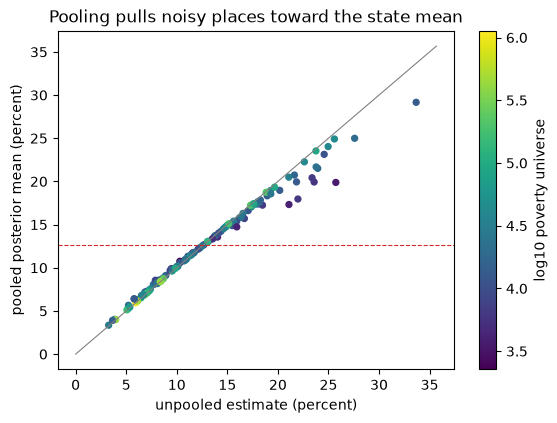

In [6]:
lo, hi = np.quantile(theta_d, 0.05, axis=0), np.quantile(theta_d, 0.95, axis=0)
pooled = theta_d.mean(axis=0)
B_draw = S[None, :] ** 2 / (S[None, :] ** 2 + tau_d[:, None] ** 2)
B_mean = B_draw.mean(axis=0)
table = pd.DataFrame({
    "place": data["place"], "population": N.astype(int), "unpooled": 100 * Y, "margin (90%)": 100 * 1.645 * S,
    "pooled": 100 * pooled, "pooled lo": 100 * lo, "pooled hi": 100 * hi, "shift (pp)": 100 * (pooled - Y),
    "width ratio": (hi - lo) / (2 * 1.645 * S), "B": B_mean,
})
tercile = pd.qcut(table["population"], 3, labels=["smallest third", "middle third", "largest third"])
by_t = table.groupby(tercile, observed=True).agg(places=("place", "size"), median_shift=("shift (pp)", lambda v: np.median(np.abs(v))),
                                                 max_shift=("shift (pp)", lambda v: np.abs(v).max()),
                                                 median_ratio=("width ratio", "median"), median_B=("B", "median"))
print("Absolute shift (pp), interval-to-margin width ratio, and shrinkage factor by population third")
print(by_t.round(3).to_string())
print(f"\nmedian absolute shift {np.median(np.abs(table['shift (pp)'])):.3f} pp; largest {np.abs(table['shift (pp)']).max():.3f} pp "
      f"({table.loc[np.abs(table['shift (pp)']).idxmax(), 'place']})")
print(f"places whose pooled interval is narrower than their margin: {(table['width ratio'] < 1).sum()} of {len(table)}")
view = table.sort_values("shift (pp)", key=np.abs, ascending=False).head(10).drop(columns=["pooled lo", "pooled hi"])
print("\nTen places the model moves most (not a ranking of places; a list of where the model matters):")
print(view.round(2).to_string(index=False))
fig, ax = plt.subplots(figsize=(6.4, 4.4))
sc = ax.scatter(100 * Y, 100 * pooled, c=np.log10(N), cmap="viridis", s=18)
lim = [0, 100 * max(Y.max(), pooled.max()) + 2]
ax.plot(lim, lim, color="grey", lw=0.8)
ax.axhline(100 * mu_d.mean(), color="C3", lw=0.8, ls="--")
ax.set(xlabel="unpooled estimate (percent)", ylabel="pooled posterior mean (percent)", title="Pooling pulls noisy places toward the state mean")
fig.colorbar(sc, label="log10 poverty universe")
plt.show()

## 4. Shrinkage against the reliability framework

Under this model the shrinkage factor `B_i` is one minus the reliability `lambda_i` that notebook D04 computes with the moment estimator of `tau`. They differ only in how `tau` is estimated: a point value from moments there, a posterior here. Notebook D04's convention publishes unit-level comparisons only where `lambda_i` is at least 0.7.

In [7]:
lam_mm = tau2_mm / (tau2_mm + S ** 2)
lam_post = 1.0 - B_mean
rho, _ = st.spearmanr(np.log(N), B_mean)
print(f"tau: posterior mean {100 * tau_d.mean():.2f} pp (90% interval {100 * np.quantile(tau_d, .05):.2f} to {100 * np.quantile(tau_d, .95):.2f}); moment estimate {100 * np.sqrt(tau2_mm):.2f} pp")
print(f"places with reliability below {LAMBDA_MIN}: {(lam_mm < LAMBDA_MIN).sum()} by the moment estimate, {(lam_post < LAMBDA_MIN).sum()} by the posterior mean of 1 - B")
print(f"median reliability: {np.median(lam_mm):.3f} by moments, {np.median(lam_post):.3f} by the posterior")
print(f"Spearman correlation of the shrinkage factor with log population: {rho:+.3f} (stated before the data to be negative)")
print(f"agreement of the two reliabilities: largest absolute difference {np.abs(lam_mm - lam_post).max():.3f}")

tau: posterior mean 5.61 pp (90% interval 5.01 to 6.28); moment estimate 5.76 pp
places with reliability below 0.7: 6 by the moment estimate, 6 by the posterior mean of 1 - B
median reliability: 0.944 by moments, 0.940 by the posterior
Spearman correlation of the shrinkage factor with log population: -0.862 (stated before the data to be negative)
agreement of the two reliabilities: largest absolute difference 0.014


## 5. Does the model describe the data it was fitted to?

A posterior predictive check: for each place, draw a replicate estimate (drawn by `pymc` from the fitted model: a draw of `theta_i` plus noise with the place's own standard error) and ask whether the published estimate lies inside the central 90% interval of the replicates. If the model is calibrated at the observed estimates, about nine in ten places should. This is a check on the model's calibration, not an out-of-sample validation.

In [8]:
rep = idata["posterior_predictive"].dataset["obs"].to_numpy().reshape(-1, len(Y))
plo, phi = np.quantile(rep, (1 - LEVEL) / 2, axis=0), np.quantile(rep, 1 - (1 - LEVEL) / 2, axis=0)
inside = (Y >= plo) & (Y <= phi)
cover = float(inside.mean())
print(f"{int(inside.sum())} of {len(Y)} published estimates lie inside their own {int(100 * LEVEL)}% posterior predictive interval: coverage {cover:.3f}")
print(f"binomial standard error of a share near {LEVEL} with {len(Y)} places: {np.sqrt(LEVEL * (1 - LEVEL) / len(Y)):.3f}")
print(f"FALSIFICATION: posterior_predictive_coverage statistic={cover:.3f} share of places inside their {int(100 * LEVEL)} percent interval; plan range {COVER_LO} to {COVER_HI} verdict={'PASS' if COVER_LO <= cover <= COVER_HI else 'FAIL'}")

133 of 133 published estimates lie inside their own 90% posterior predictive interval: coverage 1.000
binomial standard error of a share near 0.9 with 133 places: 0.026
FALSIFICATION: posterior_predictive_coverage statistic=1.000 share of places inside their 90 percent interval; plan range 0.85 to 0.95 verdict=FAIL


## 6. What the prior contributes

The same data are refitted under the four other priors fixed in the plan. For each: the posterior of `tau`, the median shrinkage, and how far any place's pooled mean moves from the primary. A place is **prior-sensitive** if its pooled mean moves by more than one percentage point across the settings. The same stop rule applies to every refit, and each is also compared with its exact calculation.

In [9]:
fits = {"primary": (tau_d, pooled, B_mean, diag["primary"])}
for label, (mp, tp) in PRIOR_SETTINGS.items():
    if label == "primary":
        continue
    tree = fit(mp, tp, Y, S)
    d = diagnostics(tree, label)
    t_d, th_d = draws_of(tree, "tau"), draws_of(tree, "theta")
    b = (S[None, :] ** 2 / (S[None, :] ** 2 + t_d[:, None] ** 2)).mean(axis=0)
    fits[label] = (t_d, th_d.mean(axis=0), b, d)
rows = []
for label, (t_d, th, b, d) in fits.items():
    change = 100 * np.abs(th - pooled)
    rows.append({"setting": label, "tau mean (pp)": 100 * t_d.mean(), "median B": np.median(b),
                 "median |change| (pp)": np.median(change), "largest |change| (pp)": change.max(),
                 "gap to exact (pp)": 100 * np.abs(th - EXACT[label].theta_mean).max(), "max R-hat": d["rhat"]})
sens = pd.DataFrame(rows)
print(sens.round(3).to_string(index=False))
tau_prior_sd = float(st.halfnorm.std(scale=0.05))
print(f"\nposterior sd of tau {tau_d.std():.4f} against its prior sd {tau_prior_sd:.4f}: contraction {tau_d.std() / tau_prior_sd:.2f}")
shifts = np.vstack([100 * np.abs(v[1] - pooled) for k, v in fits.items() if k != "primary"])
across = shifts.max(axis=0)
sensitive = np.flatnonzero(across > SENSITIVE_PP)
print(f"prior-sensitive places (pooled mean moves by more than {SENSITIVE_PP} pp across the settings): {len(sensitive)} of {len(Y)}")
if len(sensitive):
    show = pd.DataFrame({"place": data["place"][sensitive], "population": N[sensitive].astype(int), "largest change (pp)": across[sensitive]})
    print(show.sort_values("largest change (pp)", ascending=False).head(15).round(2).to_string(index=False))
vague = 100 * np.abs(fits["vague mu"][1] - pooled).max()
print(f"FALSIFICATION: prior_on_mu statistic={vague:.3f} largest change in any pooled mean between the primary and the vague-mu setting in percentage points; plan threshold {MU_TOL_PP} verdict={'PASS' if vague < MU_TOL_PP else 'FAIL'}")
share = len(sensitive) / len(Y)
print(f"share of places that are prior-sensitive: {share:.3f}; the plan reads more than a tenth as 'mostly the prior' for those places")

Initializing NUTS using jitter+adapt_diag...


Sequential sampling (4 chains in 1 job)


NUTS: [mu, tau, z]


Sampling 4 chains for 2_000 tune and 8_000 draw iterations (8_000 + 32_000 draws total) took 30 seconds.


Initializing NUTS using jitter+adapt_diag...


...

[heavy-tailed tau] largest R-hat 1.0024; smallest bulk ESS 1,423, tail ESS 2,485; divergences 0; lowest BFMI 0.67


Sequential sampling (4 chains in 1 job)


NUTS: [mu, tau, z]


Sampling 4 chains for 2_000 tune and 8_000 draw iterations (8_000 + 32_000 draws total) took 30 seconds.


[vague mu] largest R-hat 1.0018; smallest bulk ESS 1,511, tail ESS 2,506; divergences 0; lowest BFMI 0.66
         setting  tau mean (pp)  median B  median |change| (pp)  largest |change| (pp)  gap to exact (pp)  max R-hat
         primary          5.611     0.060                 0.000                  0.000              0.044      1.001
       tight tau          5.454     0.063                 0.011                  0.212              0.040      1.002
       loose tau          5.642     0.059                 0.006                  0.053              0.039      1.002
heavy-tailed tau          5.629     0.059                 0.004                  0.045              0.024      1.002
        vague mu          5.617     0.060                 0.004                  0.058              0.024      1.002

posterior sd of tau 0.0039 against its prior sd 0.0301: contraction 0.13
prior-sensitive places (pooled mean moves by more than 1.0 pp across the settings): 0 of 133
FALSIFICATION: prior_on_m

## Exploratory results

Outside the plan's report and labelled as such: the same model on the **logit scale**, which respects that a rate lies between zero and one, with standard errors by the delta method. It is compared with the primary pooled means. Nothing here is reported as a finding.

In [10]:
ADDED = "exploratory (outside the pre-specified report)"
ok = (Y > 0) & (Y < 1)
Yl, Sl = np.log(Y[ok] / (1 - Y[ok])), S[ok] / (Y[ok] * (1 - Y[ok]))
with pm.Model():
    mu_l = pm.Normal("mu", np.log(0.15 / 0.85), 0.8)
    tau_l = pm.HalfNormal("tau", 0.3)
    z_l = pm.Normal("z", 0.0, 1.0, shape=len(Yl))
    th_l = pm.Deterministic("theta", mu_l + tau_l * z_l)
    pm.Normal("obs", th_l, Sl, observed=Yl)
    tree_l = pm.sample(draws=DRAWS, tune=TUNE, chains=CHAINS, cores=1, target_accept=TARGET_ACCEPT, random_seed=SEED, progressbar=False)
diag_l = diagnostics(tree_l, "logit scale")
pooled_l = (1.0 / (1.0 + np.exp(-draws_of(tree_l, "theta")))).mean(axis=0)
diff = 100 * (pooled_l - pooled[ok])
print(f"[{ADDED}] logit-scale pooled mean minus rate-scale pooled mean: median {np.median(diff):+.3f} pp, "
      f"largest absolute {np.abs(diff).max():.3f} pp ({data['place'][np.flatnonzero(ok)[int(np.abs(diff).argmax())]]})")
print(f"[{ADDED}] places with the two disagreeing by more than {SENSITIVE_PP} pp: {int((np.abs(diff) > SENSITIVE_PP).sum())} of {int(ok.sum())}")

Initializing NUTS using jitter+adapt_diag...


Sequential sampling (4 chains in 1 job)


NUTS: [mu, tau, z]


Sampling 4 chains for 2_000 tune and 8_000 draw iterations (8_000 + 32_000 draws total) took 29 seconds.


[logit scale] largest R-hat 1.0017; smallest bulk ESS 2,983, tail ESS 5,273; divergences 0; lowest BFMI 0.68
[exploratory (outside the pre-specified report)] logit-scale pooled mean minus rate-scale pooled mean: median +0.107 pp, largest absolute 2.862 pp (Radford city)
[exploratory (outside the pre-specified report)] places with the two disagreeing by more than 1.0 pp: 9 of 133


## Limitations

- **Departure from the pre-analysis plan.** The plan was not edited. Its first fit (2000 retained draws per chain) stopped under its own stop rule: R-hat 1.0060 and no divergence, but a smallest effective sample size of 305 against the floor of 400. No number from that fit was read. Amendment 1, committed after the retrieval and before the rerun, raised the retained draws to 8000 for every fit and changed nothing else; the stop is on the run ledger. Two further readings are stated here: the plan asks for R-hat and effective sample sizes "for every place", and the notebook prints the largest R-hat and the smallest effective sample sizes over `mu`, `tau` and all 133 places, which bound every one of them; and the Census variable labels in the request are D04's own labels.
- **The margins of error are taken as known and normal.** They are themselves estimates, and the 90% margins are converted to standard errors by dividing by 1.645.
- **The rate-scale model ignores that a rate lies between zero and one.** The exploratory logit-scale refit moves 9 of 133 places by more than one percentage point, the largest being Radford city, which is among the highest-poverty places; the normal form on the rate scale is a modelling choice with consequences at the top of the distribution.
- **Counties are shrunk toward the state mean, not toward similar counties.** There are no covariates and no spatial structure, so a high-poverty place is pulled toward a state mean that may say little about it. The largest shifts (Norton city, Radford city, Buena Vista city) are all places that sit far above the state mean.
- **Independent cities and counties are treated as exchangeable.**
- **One planned check failed, and the others do not make up for it.** The posterior predictive coverage check returned 133 of 133 places inside their interval, against a planned range of 0.85 to 0.95. The interval it uses adds a posterior draw of the place's rate to noise at the place's own standard error, so it is wide by construction and cannot detect a model that is too narrow. The calibration of the model at the observed estimates is therefore not established here.
- **The 5-year estimates pool 2019 to 2023** and describe none of those years in particular. The pooled estimates are model outputs that depend on the prior; the unpooled estimates remain the design-based quantity and are shown beside them.
- **Sampling is seeded, but draw-based numbers can differ in the last digits across platforms and library versions** (pymc 6.3.2, ArviZ 1.3.0 here), which is why every check is a threshold and not an equality.

## Key Takeaways

1. **Pooling changes little where the data are precise and a good deal where they are not.** The median absolute shift is 0.175 percentage points. In the smallest third of places by population it is 0.364 and the largest shift is 5.85 (Norton city: 25.73 unpooled, 19.88 pooled); in the largest third it is 0.069 and the largest is 0.93. The pooled 90% interval is narrower than the published margin in 128 of 133 places.
2. **The shrinkage agrees with the corpus's reliability framework.** The posterior mean of between-county spread is 5.61 points (90% interval 5.01 to 6.28) against D04's moment estimate of 5.76. Six places have reliability below 0.7 by either measure, and the shrinkage factor falls with population (Spearman -0.862, as stated before the data).
3. **The sampler is right for this model.** The largest gap between the sampler's posterior mean of any place and the exact calculation is 0.044 points against a threshold of 0.1; the largest R-hat is 1.0014 and the smallest effective sample size is 1,496, with no divergence. The first fit, with a quarter of the draws, stopped on its effective-sample-size floor, and the amendment that fixed it is part of the record.
4. **The prior contributes little to these pooled estimates.** The posterior of the between-county spread is 0.13 times as wide as its prior. No place moves by more than one point across the four alternative priors (the largest change is 0.21 points, under the tight prior on the spread), and the vague prior on the mean moves nothing by more than 0.058. What does matter is the form of the model: on the logit scale 9 places move by more than a point (exploratory).
5. **One planned check failed.** The posterior predictive coverage is 133 of 133 against a planned range of 0.85 to 0.95. It is reported as failed; the check is too wide to detect miscalibration, so this notebook does not establish that the model is calibrated at the observed estimates.
6. **A pooled estimate is a model output.** It is a prediction of a county's rate under stated assumptions, shown beside the design-based estimate and not in place of it. No county is ranked.

## Exercises

1. Change the prior on `tau` to `HalfNormal(0.01)` in a new amendment file, committed before you compute anything, and say which places become prior-sensitive.
2. Add the county's median household income as a covariate for `mu` (a regression of the mean on income, as in D10's data) and say what the shrinkage factor is now shrinking toward.
3. Why can the pooled interval of a county be narrower than its published margin without the county having been measured more precisely? What would it take for the pooled interval to be wider?

## References

Author, year and venue as recalled; **not verified against the source in this build.** Gelman, A. and Hill, J. (2007), *Data Analysis Using Regression and Multilevel/Hierarchical Models*, Cambridge University Press. Gelman, A. (2006), "Prior distributions for variance parameters in hierarchical models", *Bayesian Analysis*. Efron, B. and Morris, C. (1975), "Data analysis using Stein's estimator and its generalizations", *Journal of the American Statistical Association*. Vehtari, A., Gelman, A., Simpson, D., Carpenter, B. and Burkner, P.-C. (2021), "Rank-normalization, folding, and localization: an improved R-hat", *Bayesian Analysis*. U.S. Census Bureau, *Understanding and Using American Community Survey Data: What All Data Users Need to Know* (the formula for the standard error of a proportion).